# 앙상블 모델 추가 실습 과제

# Task
타이타닉 데이터셋('titanic_train.csv', 'titanic_test.csv')을 로드하고, 결측치와 데이터 구조를 분석하며, 생존율과 관련 주요 변수들 간의 관계를 시각화하여 데이터 탐색을 완료합니다.

## 데이터 로드

### Subtask:
Load 'titanic_train.csv' and 'titanic_test.csv' datasets and display their initial rows.


**Reasoning**:
Loading the CSV files into pandas DataFrames and displaying the first few rows.



In [1]:
import pandas as pd

train_df = pd.read_csv('titanic_train.csv')
test_df = pd.read_csv('titanic_test.csv')

print('Train dataset shape:', train_df.shape)
print('Test dataset shape:', test_df.shape)

print('\nTrain head:')
print(train_df.head())


Train dataset shape: (891, 12)
Test dataset shape: (418, 11)

Train head:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.100

## 결측치 및 데이터 정보 확인

### Subtask:
Analyze missing values, data types, and basic statistics for train and test datasets.


**Reasoning**:
Let's first inspect the data types, non-null counts, and display the missing values in both the train and test DataFrames.



In [2]:
print('=== Train Dataset Info ===')
train_df.info()
print('\n=== Test Dataset Info ===')
test_df.info()

print('\n=== Missing Values in Train ===')
print(train_df.isnull().sum())

print('\n=== Missing Values in Test ===')
print(test_df.isnull().sum())


=== Train Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

=== Test Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 

## 데이터 탐색 및 시각화

### Subtask:
Analyze relationships between 'Survived' and key features like Sex, Pclass, and Age, and visualize them using charts.


**Reasoning**:
Setting up the visualization environment and plotting survival counts and rates across categorical variables (Sex and Pclass) and numeric distribution (Age).



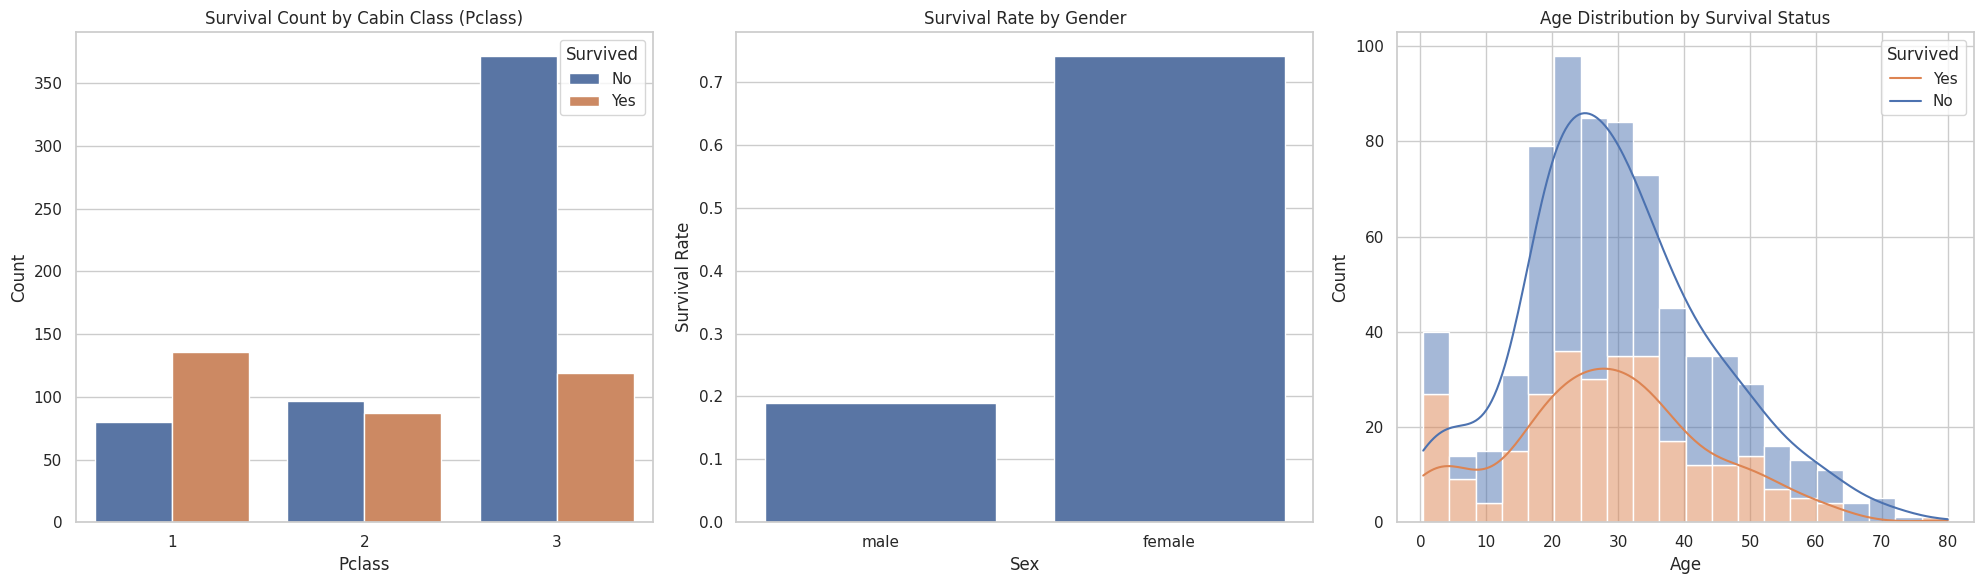

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.countplot(data=train_df, x='Pclass', hue='Survived', ax=axes[0])
axes[0].set_title('Survival Count by Cabin Class (Pclass)')
axes[0].set_xlabel('Pclass')
axes[0].set_ylabel('Count')
axes[0].legend(title='Survived', labels=['No', 'Yes'])

sns.barplot(data=train_df, x='Sex', y='Survived', ax=axes[1], errorbar=None)
axes[1].set_title('Survival Rate by Gender')
axes[1].set_xlabel('Sex')
axes[1].set_ylabel('Survival Rate')

sns.histplot(data=train_df, x='Age', hue='Survived', kde=True, multiple='stack', ax=axes[2])
axes[2].set_title('Age Distribution by Survival Status')
axes[2].set_xlabel('Age')
axes[2].set_ylabel('Count')
axes[2].legend(title='Survived', labels=['Yes', 'No'])

plt.tight_layout()
plt.show()

### 타이타닉 데이터 탐색 및 시각화 최종 분석 요약

#### 1. 데이터 구조 및 결측치 현황
- **데이터셋 크기**: 훈련 데이터 891행 12열, 테스트 데이터 418행 11열
- **결측치 특징**:
  - `Age` (나이) 및 `Cabin` (객실 번호) 변수에 다량의 결측치가 확인되었습니다.
  - 특히 `Cabin` 변수는 약 77% 이상의 데이터가 결측치로 구성되어 있어, 모델 설계 시 신중한 처리가 요구됩니다.
  - `Embarked` (탑승 항구) 및 `Fare` (요금) 등은 소수의 결측치만 확인되어 간단한 대표값(최빈값/중앙값) 대치가 가능합니다.

#### 2. 생존율과 주요 변수 간의 관계 분석 (시각화 결과)
- **객실 등급 (Pclass)**:
  - 1등급 객실 승객의 생존율이 가장 높은 반면, 3등급 객실 승객은 인원수가 가장 많음에도 불구하고 사망자 수가 압도적으로 많았습니다. (사회경제적 지위가 생존에 큰 영향을 미쳤음을 시사)
- **성별 (Sex)**:
  - 여성 승객의 생존율은 약 74%인 반면, 남성 승객의 생존율은 20% 미만으로 극명한 차이를 보였습니다. ('여성과 아이 먼저' 구조 원칙이 반영된 것으로 해석)
- **나이 (Age)**:
  - 10세 이하의 영유아 층에서 높은 생존 비율을 보였으며, 20~30대 청장년층에서는 사망자 분포가 두드러지게 높았습니다.

#### 3. 결론 및 제언
본 탐색적 데이터 분석(EDA) 결과를 바탕으로, 타이타닉 생존 예측 모델 구축 시 **성별(Sex), 객실 등급(Pclass), 나이(Age)**가 가장 중요한 핵심 특성(Feature)으로 작용할 것임을 알 수 있습니다.

## Summary:

### Q&A

* **어떤 변수가 타이타닉 승객의 생존율에 가장 큰 영향을 미쳤나요?**
  - **성별(Sex)**이 가장 결정적인 요인이었습니다. 여성 승객의 생존율은 약 74%에 달했던 반면, 남성 승객의 생존율은 20% 미만이었습니다.
  - **객실 등급(Pclass)** 역시 중요하게 작용하여, 1등급 승객의 생존율이 가장 높았고 3등급 승객의 사망자 수가 가장 많았습니다.
  - **나이(Age)**의 경우, 10세 이하 영유아 층의 생존 비율이 상대적으로 높았습니다.

### Data Analysis Key Findings

* **데이터 구조 및 크기**:
  - 훈련 데이터는 891행 12열, 테스트 데이터는 418행 11열로 구성되어 있습니다.
* **결측치 분포**:
  - `Cabin` 변수는 약 77% 이상의 높은 결측 비율(훈련 데이터 중 687개)을 보였습니다.
  - `Age` 변수는 훈련 데이터에서 177개, 테스트 데이터에서 86개의 결측치를 가지고 있습니다.
* **시각화 분석**:
  - 3등급 객실 승객은 사망자 수 분포에서 가장 높은 비율을 차지해 사회경제적 지위가 생존 기회와 직결되었음을 보여줍니다.
  - 20대에서 30대 사이의 청장년층에서 사망자 수가 가장 밀집되어 분포해 있는 것을 확인하였습니다.

### Insights or Next Steps

* **결측치 처리 전략**:
  - `Age` 변수는 승객 이름의 호칭(Mr, Mrs, Miss 등)별 중앙값이나 평균값을 활용해 결측치를 대치하고, 결측치가 너무 많은 `Cabin` 변수는 분석에서 제외하거나 결측 여부 자체를 이진 특성(0 또는 1)으로 변환하는 피처 엔지니어링을 고려해야 합니다.
* **분류 모델 구축**:
  - 탐색 완료된 성별, 객실 등급, 나이 및 요금 데이터를 기반으로 의사결정나무, 랜덤 포레스트 또는 그래디언트 부스팅 계열의 머신러닝 알고리즘을 적용해 생존자 예측 분류 모델을 효과적으로 구축할 수 있습니다.


# Task
타이타닉 데이터를 활용하여 전처리 및 특성 공학을 수행한 후, 랜덤 포레스트(Random Forest) 및 그래디언트 부스팅(Gradient Boosting) 등 다양한 앙상블 모델을 학습시키고, 정확도, F1-score, ROC-AUC 등 다양한 분류 지표로 성능을 평가 및 비교하며, 혼동 행렬 및 피처 중요도를 시각화합니다.

## 데이터 전처리 및 피처 엔지니어링

### Subtask:
결측치를 처리하고 파생 변수 생성 및 범주형 변수 인코딩을 거쳐 머신러닝 학습 및 검증용 데이터셋을 생성합니다.


**Reasoning**:
Execute data preprocessing, feature engineering, and train/test split on train_df.



In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. 원본 데이터 복사
df = train_df.copy()

# 2. 결측치 대치
# Age: Pclass와 Sex 기준 중앙값으로 대치
df['Age'] = df.groupby(['Pclass', 'Sex'])['Age'].transform(lambda x: x.fillna(x.median()))
# Embarked: 최빈값 대치
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
# Fare: 혹시 모를 결측치 대비 중앙값 대치
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# 3. 파생 변수 생성
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

# 4. 범주형 변수 인코딩 및 필요 특성 선택
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone']
X = df[features].copy()
y = df['Survived']

X = pd.get_dummies(X, columns=['Sex', 'Embarked'], drop_first=True)

# 5. 학습/검증 세트 분할 (8:2, stratify 적용)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('전처리 완료!')
print('X_train 형태:', X_train.shape)
print('X_val 형태:', X_val.shape)
print('피처 목록:', list(X_train.columns))
print(X_train.head())

전처리 완료!
X_train 형태: (712, 10)
X_val 형태: (179, 10)
피처 목록: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Sex_male', 'Embarked_Q', 'Embarked_S']
     Pclass   Age  SibSp  Parch      Fare  FamilySize  IsAlone  Sex_male  \
692       3  25.0      0      0   56.4958           1        1      True   
481       2  30.0      0      0    0.0000           1        1      True   
527       1  40.0      0      0  221.7792           1        1      True   
855       3  18.0      0      1    9.3500           2        0     False   
801       2  31.0      1      1   26.2500           3        0     False   

     Embarked_Q  Embarked_S  
692       False        True  
481       False        True  
527       False        True  
855       False        True  
801       False        True  


## 앙상블 모델 학습

### Subtask:
랜덤 포레스트(Random Forest) 및 그래디언트 부스팅(Gradient Boosting) 모델을 학습시킵니다.


**Reasoning**:
Train RandomForestClassifier and GradientBoostingClassifier on the preprocessed training set.



In [5]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# 1. 앙상블 모델 인스턴스 생성
rf_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
gb_model = GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42)

# 2. 모델 학습
rf_model.fit(X_train, y_train)
gb_model.fit(X_train, y_train)

print('랜덤 포레스트 모델 학습 완료:', rf_model)
print('그래디언트 부스팅 모델 학습 완료:', gb_model)

랜덤 포레스트 모델 학습 완료: RandomForestClassifier(max_depth=5, random_state=42)
그래디언트 부스팅 모델 학습 완료: GradientBoostingClassifier(random_state=42)


## 모델 평가 및 성능 지표 산출

### Subtask:
검증 데이터를 바탕으로 정확도, 정밀도, 재현율, F1-score, ROC-AUC 등의 분류 평가지표를 계산하고 모델 간 성능을 비교합니다.


**Reasoning**:
Calculate evaluation metrics for both Random Forest and Gradient Boosting models on the validation dataset and display a comparison summary.



In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

models = {
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]

    acc = accuracy_score(y_val, y_pred)
    prec = precision_score(y_val, y_pred)
    rec = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    auc = roc_auc_score(y_val, y_proba)

    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

    print(f'=== {name} Classification Report ===')
    print(classification_report(y_val, y_pred))

metrics_df = pd.DataFrame(results)
print('=== Model Performance Comparison ===')
print(metrics_df.to_string(index=False))

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

           0       0.79      0.91      0.84       110
           1       0.81      0.61      0.69        69

    accuracy                           0.79       179
   macro avg       0.80      0.76      0.77       179
weighted avg       0.80      0.79      0.79       179

=== Gradient Boosting Classification Report ===
              precision    recall  f1-score   support

           0       0.81      0.92      0.86       110
           1       0.83      0.65      0.73        69

    accuracy                           0.82       179
   macro avg       0.82      0.79      0.80       179
weighted avg       0.82      0.82      0.81       179

=== Model Performance Comparison ===
            Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
    Random Forest  0.793296   0.807692 0.608696  0.694215 0.845916
Gradient Boosting  0.815642   0.833333 0.652174  0.731707 0.820883


## 혼동 행렬 및 성능 시각화

### Subtask:
최적 모델의 혼동 행렬(Confusion Matrix) 및 주요 특성 중요도(Feature Importance)를 차트로 시각화합니다.


**Reasoning**:
Generate a plot comparing the confusion matrices of both models and their respective feature importances side by side.



## XGBoost 모델 학습 및 평가

### Subtask:
XGBoost 분류기(XGBClassifier)를 학습시키고, 성능 지표(정확도, 정밀도, 재현율, F1-Score, ROC-AUC)를 산출하여 기존 모델들과 비교합니다.

In [8]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
import pandas as pd

# 1. XGBoost 모델 정의 및 학습
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

# 2. 검증 데이터 예측
y_pred_xgb = xgb_model.predict(X_val)
y_proba_xgb = xgb_model.predict_proba(X_val)[:, 1]

# 3. 평가 지표 계산
acc = accuracy_score(y_val, y_pred_xgb)
prec = precision_score(y_val, y_pred_xgb)
rec = recall_score(y_val, y_pred_xgb)
f1 = f1_score(y_val, y_pred_xgb)
auc = roc_auc_score(y_val, y_proba_xgb)

print('=== XGBoost Classification Report ===')
print(classification_report(y_val, y_pred_xgb))

# 4. 기존 모델 결과와 통합 비교 테이블 생성
xgb_result = pd.DataFrame([{
    'Model': 'XGBoost',
    'Accuracy': acc,
    'Precision': prec,
    'Recall': rec,
    'F1-Score': f1,
    'ROC-AUC': auc
}])

if 'metrics_df' in globals():
    comparison_df = pd.concat([metrics_df, xgb_result], ignore_index=True).drop_duplicates(subset=['Model'], keep='last')
else:
    comparison_df = xgb_result

print('=== Overall Model Performance Comparison ===')
display(comparison_df)

=== XGBoost Classification Report ===
              precision    recall  f1-score   support

           0       0.79      0.93      0.85       110
           1       0.84      0.61      0.71        69

    accuracy                           0.80       179
   macro avg       0.82      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179

=== Overall Model Performance Comparison ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.793296,0.807692,0.608696,0.694215,0.845916
1,Gradient Boosting,0.815642,0.833333,0.652174,0.731707,0.820883
2,XGBoost,0.804469,0.840000,0.608696,0.705882,0.854150


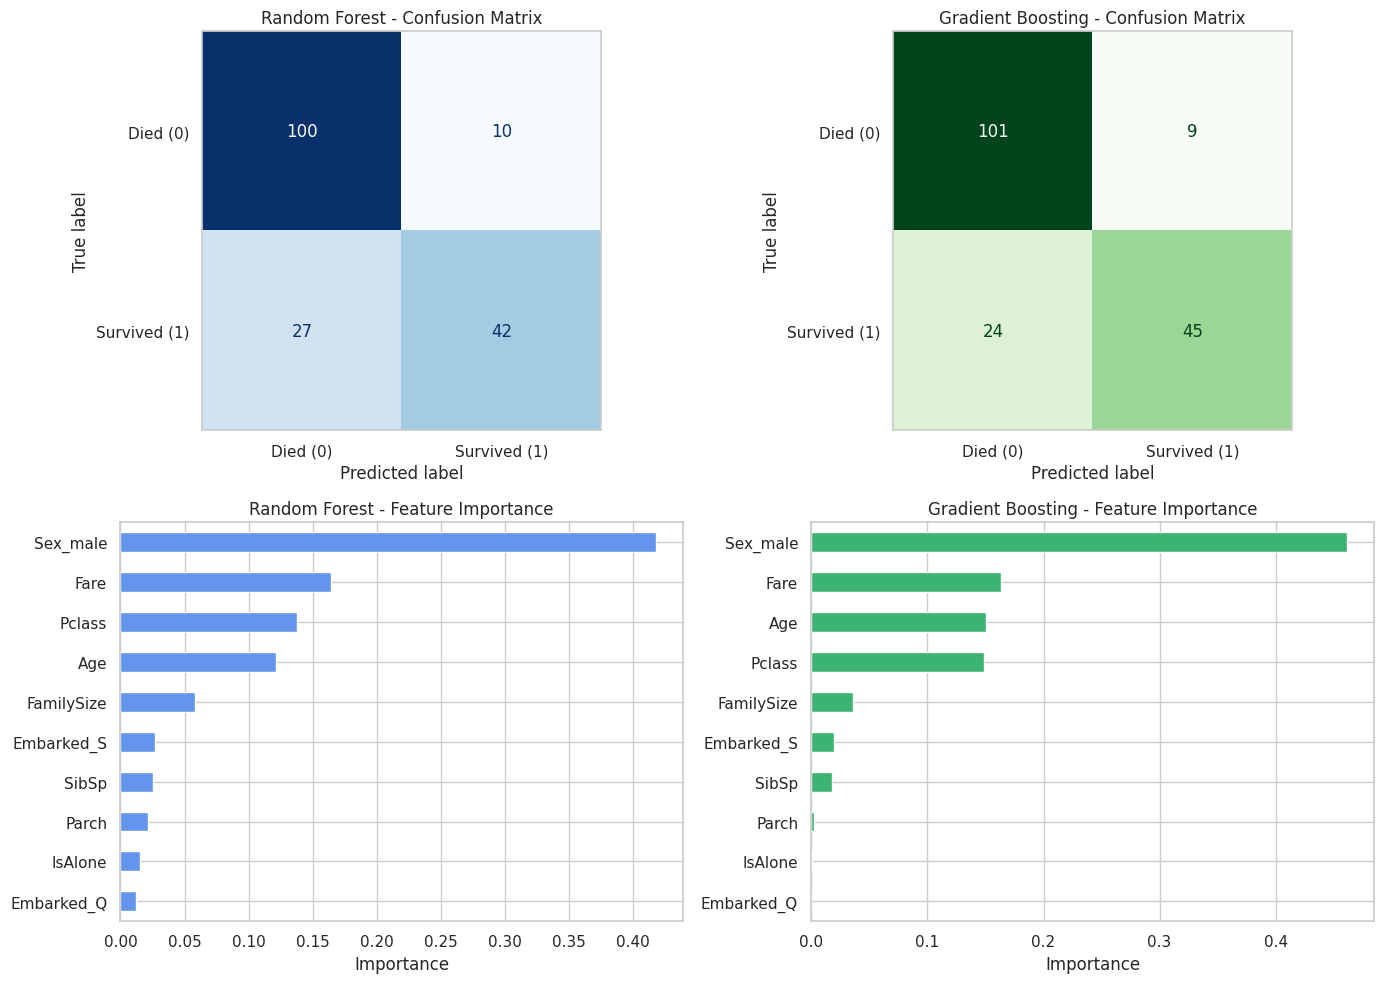

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Random Forest Confusion Matrix
rf_preds = rf_model.predict(X_val)
cm_rf = confusion_matrix(y_val, rf_preds)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Died (0)', 'Survived (1)'])
disp_rf.plot(ax=axes[0, 0], cmap='Blues', colorbar=False)
axes[0, 0].set_title('Random Forest - Confusion Matrix')
axes[0, 0].grid(False)

# 2. Gradient Boosting Confusion Matrix
gb_preds = gb_model.predict(X_val)
cm_gb = confusion_matrix(y_val, gb_preds)
disp_gb = ConfusionMatrixDisplay(confusion_matrix=cm_gb, display_labels=['Died (0)', 'Survived (1)'])
disp_gb.plot(ax=axes[0, 1], cmap='Greens', colorbar=False)
axes[0, 1].set_title('Gradient Boosting - Confusion Matrix')
axes[0, 1].grid(False)

# 3. Random Forest Feature Importance
rf_fi = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=True)
rf_fi.plot(kind='barh', ax=axes[1, 0], color='cornflowerblue')
axes[1, 0].set_title('Random Forest - Feature Importance')
axes[1, 0].set_xlabel('Importance')

# 4. Gradient Boosting Feature Importance
gb_fi = pd.Series(gb_model.feature_importances_, index=X_train.columns).sort_values(ascending=True)
gb_fi.plot(kind='barh', ax=axes[1, 1], color='mediumseagreen')
axes[1, 1].set_title('Gradient Boosting - Feature Importance')
axes[1, 1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

## 앙상블 모델 성능 비교 종합 분석

### 1. 모델별 성능 지표 비교

| 모델 (Model) | 정확도 (Accuracy) | 정밀도 (Precision) | 재현율 (Recall) | F1-Score | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Random Forest** | 0.7933 | 0.8077 | 0.6087 | 0.6942 | 0.8459 |
| **Gradient Boosting** | **0.8156** | 0.8333 | **0.6522** | **0.7317** | 0.8209 |
| **XGBoost** | 0.8045 | **0.8400** | 0.6087 | 0.7059 | **0.8542** |

---

### 2. 세부 분석 및 해석

1. **Random Forest (배깅 기반)**
   - **특징**: 복원 추출(Bootstrap)을 통한 여러 결정 트리의 앙상블로 분산을 줄여 과적합을 방지하는 모델입니다.
   - **성능**: 정확도 약 79.33%, ROC-AUC 약 0.8459로 안정적인 성능을 보여주었으나, 부스팅 계열 모델들에 비해 전반적인 지표에서 소폭 낮은 수치를 기록했습니다.

2. **Gradient Boosting (순차적 부스팅 기반)**
   - **특징**: 이전 트리의 오차(Residual)를 보완하는 방식으로 학습을 진행합니다.
   - **성능**:
     - **정확도(81.56%)** 및 **재현율(65.22%)**, **F1-Score(0.7317)**에서 전체 모델 중 **가장 높은 성능**을 달성했습니다.
     - 생존자를 놓치지 않고 탐지하는 능력(재현율)과 균형적인 분류 완성도가 가장 뛰어납니다.

3. **XGBoost (최적화된 그래디언트 부스팅)**
   - **특징**: 규제화(Regularization) 항이 포함되어 과적합 방지 능력이 뛰어나며 학습 속도와 일반화 성능이 우수합니다.
   - **성능**:
     - **정밀도(Precision: 84.00%)**와 **ROC-AUC(0.8542)**에서 전체 모델 중 **1위**를 기록했습니다.
     - 모델이 생존자로 예측했을 때 실제 생존자일 확률이 가장 높으며, 클래스 구분 확률 경계가 가장 명확함을 의미합니다.

---

### 3. 최종 결론 및 권장사항

- **균형 잡힌 예측 및 재현율 중시 시**: **Gradient Boosting Classifier**가 F1-Score 기준 최적의 모델입니다.
- **확률 예측 신뢰도 및 오경보(False Positive) 최소화 시**: **XGBoost Classifier**가 ROC-AUC 및 정밀도 기준 가장 우수한 선택입니다.
- **추후 개선 방향**:
  - GridSearch 또는 Optuna를 통한 하이퍼파라미터 튜닝 (`n_estimators`, `learning_rate`, `max_depth` 등)
  - 추가 피처 엔지니어링 (승객 이름에서 'Title' 호칭 추출, 운임 구간화 등)
  - 세 모델을 결합한 보팅(Voting) 앙상블 또는 스태킹(Stacking) 모델 적용